In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter, defaultdict
from tqdm.notebook import tqdm

In [2]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT.parent / "data"/ "junction-dataset-preview"
QUESTIONS_FILE = DATA_DIR / "questions.jsonl"

# for entrie in DATA_DIR.iterdir():
#     print(entrie)

sns.set_theme(style="whitegrid")

print("Project root:", PROJECT_ROOT)
print("Data directory exists:", DATA_DIR.exists())
print("Questions file exists:", QUESTIONS_FILE.exists())

Project root: c:\Users\DV285061\Desktop\project\hackjunction-nov26\notebook
Data directory exists: True
Questions file exists: True


In [3]:
questions = pd.read_json(QUESTIONS_FILE, lines=True)

print("Number of questions:", len(questions))
display(questions.head(10))
display(questions.info())

Number of questions: 7990


,path,question,answer,unit,type
0,data/cubicasa5k/colorful-11397.png,How many windows are shown on this floor plan?,13,count,count
1,data/cubicasa5k/colorful-11397.png,Kuinka monta ikkunaa pohjapiirustuksessa on?,13,count,count
2,data/cubicasa5k/colorful-11397.png,How many toilet bowls (WC seats) are drawn on ...,2,count,count
3,data/cubicasa5k/colorful-11397.png,Kuinka monta WC-istuinta pohjapiirustukseen on...,2,count,count
4,data/cubicasa5k/colorful-11397.png,How many sinks and wash basins (kitchen and ba...,3,count,count
5,data/cubicasa5k/colorful-11397.png,Kuinka monta pesu- ja tiskiallasta (keittiö ja...,3,count,count
6,data/cubicasa5k/colorful-11397.png,How many showers and bathtubs are drawn on thi...,3,count,count
7,data/cubicasa5k/colorful-11397.png,Kuinka monta suihkua ja kylpyammetta pohjapiir...,3,count,count
8,data/cubicasa5k/colorful-11397.png,How many floors (storeys) does this floor plan...,2,count,count
9,data/cubicasa5k/colorful-11397.png,Kuinka monta kerrosta pohjapiirustuksessa on e...,2,count,count


<class 'pandas.DataFrame'>
RangeIndex: 7990 entries, 0 to 7989
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   path      7990 non-null   str   
 1   question  7990 non-null   str   
 2   answer    7990 non-null   object
 3   unit      7725 non-null   str   
 4   type      7990 non-null   str   
dtypes: object(1), str(4)
memory usage: 312.2+ KB


None

,count
type,
count,6076
area,1599
text,265
volume,34
length,16


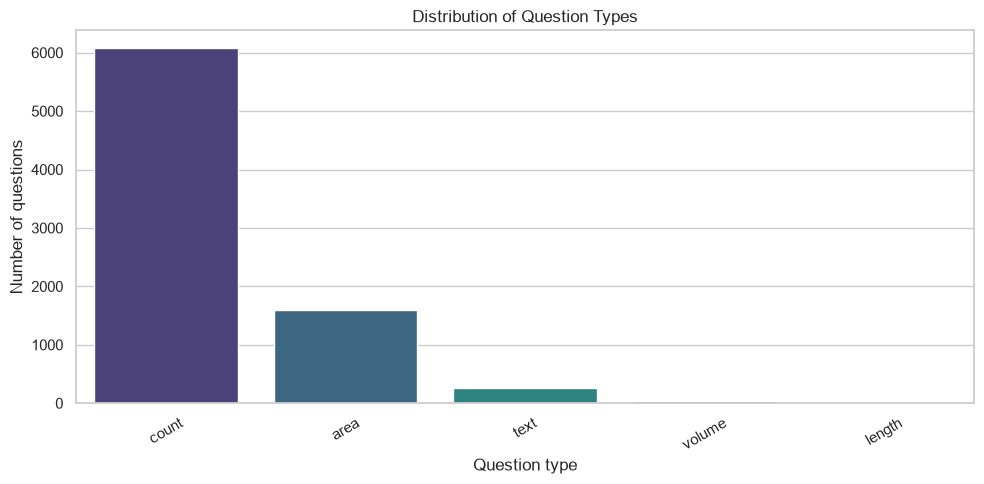

In [4]:
type_counts = questions["type"].value_counts()

display(type_counts.to_frame("count"))

plt.figure(figsize=(10, 5))
sns.barplot(
    x=type_counts.index,
    y=type_counts.values,
    hue=type_counts.index,
    palette="viridis",
    legend=False
)

plt.title("Distribution of Question Types")
plt.xlabel("Question type")
plt.ylabel("Number of questions")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


,count
unit,
count,6076
m2,1590
NaN,265
m3,34
m,16
ft2,9


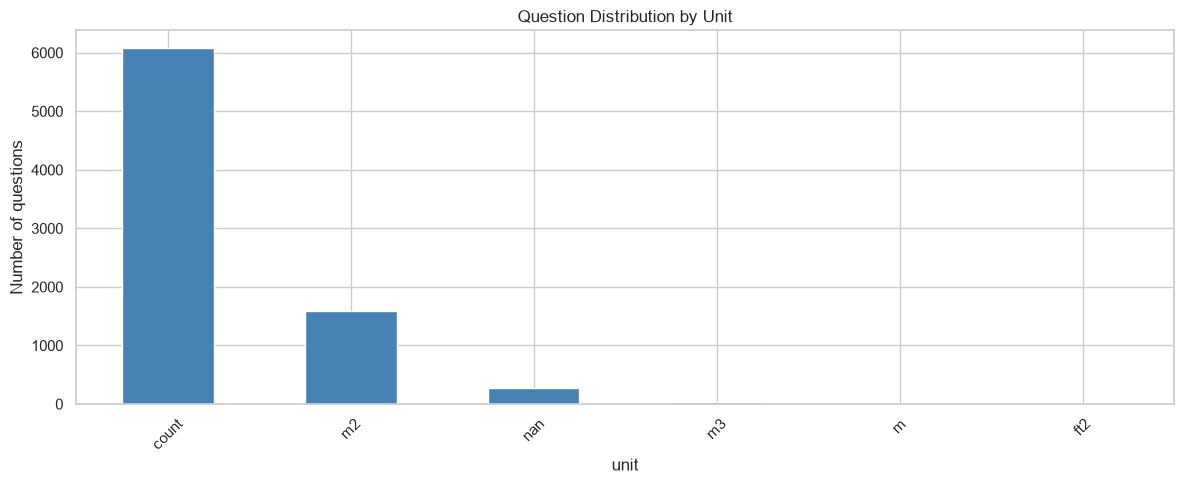

In [5]:

unit_counts = questions["unit"].value_counts(dropna=False)

display(unit_counts.to_frame("count"))

plt.figure(figsize=(12, 5))
unit_counts.plot(kind="bar", color="steelblue")
plt.title("Question Distribution by Unit")
plt.ylabel("Number of questions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [6]:

for question_type in ["count", "area", "length", "volume"]:
    subset = questions[questions["type"] == question_type].copy()

    numeric_answers = pd.to_numeric(
        subset["answer"],
        errors="coerce"
    ).dropna()

    print(f"\n{question_type.upper()}")
    print(numeric_answers.describe(percentiles=[
        0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99
    ]))



COUNT
count    6076.000000
mean        5.328835
std        23.466881
min         0.000000
1%          0.000000
5%          0.000000
25%         1.000000
50%         2.000000
75%         4.000000
95%        18.000000
99%        46.000000
max       846.000000
Name: answer, dtype: float64

AREA
count     1599.000000
mean       127.956120
std       1462.454236
min          1.510000
1%           2.199400
5%           3.670000
25%          5.825000
50%         23.610000
75%         72.170000
95%        301.211000
99%        859.310000
max      49560.000000
Name: answer, dtype: float64

LENGTH
count     16.000000
mean     179.739375
std       75.436231
min       42.800000
1%        42.800000
5%        42.800000
25%      156.207750
50%      226.101500
75%      229.413000
95%      229.513000
99%      229.513000
max      229.513000
Name: answer, dtype: float64

VOLUME
count     34.000000
mean     164.635824
std       74.693101
min       15.202000
1%        15.202000
5%        35.669850
25%     

## notebook2

In [7]:
SUPPORTED_EXTENSIONS = {
    ".pdf", ".dwg", ".dxf", ".ifc",
    ".svg", ".png", ".jpg", ".jpeg"
}

file_records = []

for source_dir in DATA_DIR.iterdir():
    if not source_dir.is_dir():
        continue

    for file_path in source_dir.rglob("*"):
        if file_path.is_file() and file_path.suffix.lower() in SUPPORTED_EXTENSIONS:
            file_records.append({
                "source": source_dir.name,
                "filename": file_path.name,
                "stem": file_path.stem,
                "extension": file_path.suffix.lower(),
                "size_mb": file_path.stat().st_size / (1024 ** 2),
                "path": str(file_path.relative_to(DATA_DIR))
            })

files = pd.DataFrame(file_records)

print("Total drawing files:", len(files))
display(files)

Total drawing files: 913


,source,filename,stem,extension,size_mb,path
0,data,colorful-11397.png,colorful-11397,.png,0.042681,data\cubicasa5k\colorful-11397.png
1,data,colorful-11400.png,colorful-11400,.png,0.343453,data\cubicasa5k\colorful-11400.png
2,data,colorful-11960.png,colorful-11960,.png,0.013049,data\cubicasa5k\colorful-11960.png
3,data,colorful-12200.png,colorful-12200,.png,0.083080,data\cubicasa5k\colorful-12200.png
4,data,colorful-13685.png,colorful-13685,.png,0.571638,data\cubicasa5k\colorful-13685.png
...,...,...,...,...,...,...
908,data,The Downtowner_ARCH - Sheet - S500 - FRAMING S...,The Downtowner_ARCH - Sheet - S500 - FRAMING S...,.pdf,0.206672,data\opening_design\Vacation_Rental\Transfer\2...
909,data,The Downtowner_ARCH_2D and Schedules - Sheet -...,The Downtowner_ARCH_2D and Schedules - Sheet -...,.pdf,0.707224,data\opening_design\Vacation_Rental\Transfer\2...
910,data,The_Downtowner_PLMB_ZS - Sheet - P0-00 - PLUMB...,The_Downtowner_PLMB_ZS - Sheet - P0-00 - PLUMB...,.pdf,0.606833,data\opening_design\Vacation_Rental\Transfer\2...
911,data,13.pdf,13,.pdf,0.133116,data\opening_design\Vacation_Rental\Transfer\2...


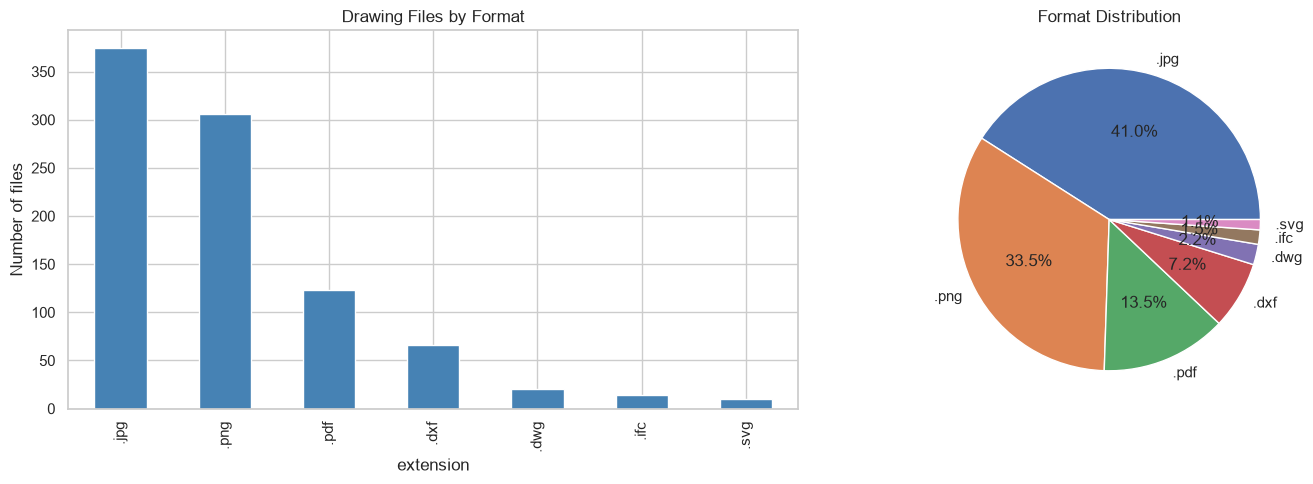

In [8]:

format_counts = files["extension"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

format_counts.plot(
    kind="bar",
    ax=axes[0],
    color="steelblue"
)
axes[0].set_title("Drawing Files by Format")
axes[0].set_ylabel("Number of files")

format_counts.plot(
    kind="pie",
    ax=axes[1],
    autopct="%1.1f%%"
)
axes[1].set_title("Format Distribution")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()


extension,.dwg,.dxf,.ifc,.jpg,.pdf,.png,.svg
source,,,,,,,
data,20,66,14,374,123,306,10


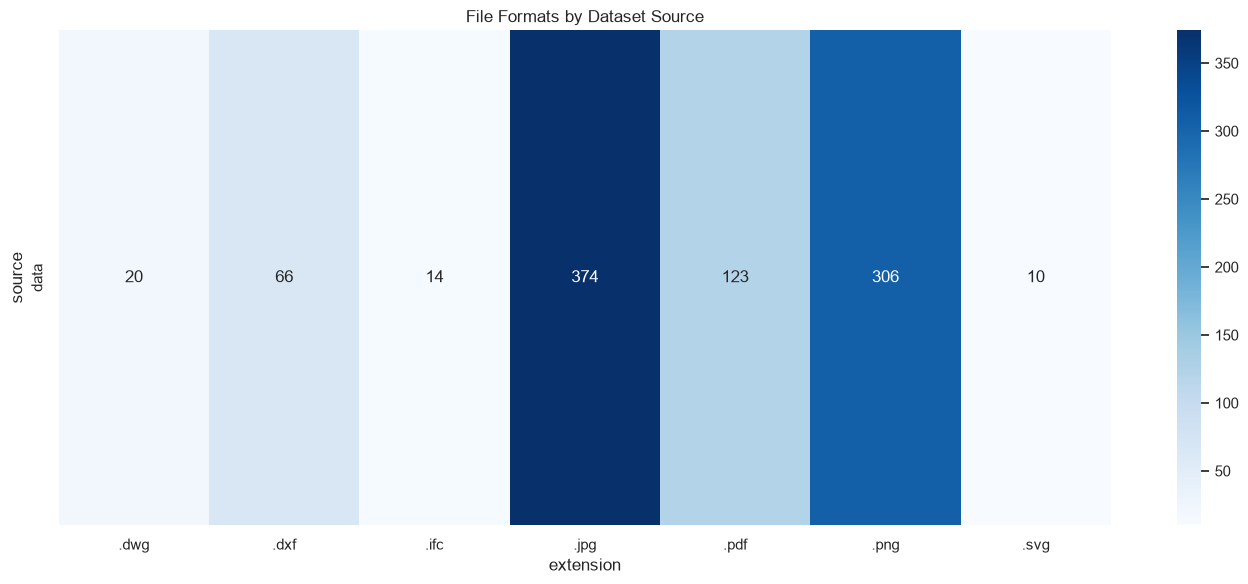

In [9]:

source_format = pd.crosstab(
    files["source"],
    files["extension"]
)

display(source_format)

plt.figure(figsize=(14, 6))
sns.heatmap(
    source_format,
    annot=True,
    fmt="g",
    cmap="Blues"
)
plt.title("File Formats by Dataset Source")
plt.tight_layout()
plt.show()


## Notebook3

In [10]:

format_matrix = (
    files.groupby(["source", "stem"])["extension"]
    .agg(lambda x: sorted(set(x)))
    .reset_index(name="formats")
)

format_matrix["format_count"] = format_matrix["formats"].apply(len)

multi_format = format_matrix[
    format_matrix["format_count"] > 1
].sort_values("format_count", ascending=False)

print("Drawings with multiple formats:", len(multi_format))
display(multi_format.head(30))


Drawings with multiple formats: 75


,source,stem,formats,format_count
679,data,site1000_bldg2082_floor9385,"[.dxf, .pdf, .png]",3
689,data,site1138_bldg2292_floor10584,"[.dxf, .pdf, .png]",3
688,data,site11265_bldg17059_floor45087,"[.dxf, .pdf, .png]",3
687,data,site1110_bldg2250_floor10322,"[.dxf, .pdf, .png]",3
686,data,site1102_bldg2242_floor10281,"[.dxf, .pdf, .png]",3
685,data,site1101_bldg2241_floor10275,"[.dxf, .pdf, .png]",3
684,data,site1098_bldg2234_floor10334,"[.dxf, .pdf, .png]",3
683,data,site1088_bldg2216_floor10132,"[.dxf, .pdf, .png]",3
682,data,site1047_bldg2154_floor9740,"[.dxf, .pdf, .png]",3
681,data,site1040_bldg2136_floor9659,"[.dxf, .pdf, .png]",3


In [11]:

ifc_files = files[files["extension"] == ".ifc"]
pdf_files = files[files["extension"] == ".pdf"]

ifc_stems = set(ifc_files["stem"])

pdf_files = pdf_files.copy()

pdf_files["possible_ifc_model"] = (
    pdf_files["stem"]
    .str.replace(r"_.*$", "", regex=True)
)

pdf_ifc_candidates = pdf_files[
    pdf_files["possible_ifc_model"].isin(ifc_stems)
]

display(pdf_ifc_candidates[
    ["filename", "possible_ifc_model", "source"]
].head(30))


,filename,possible_ifc_model,source


## notebook 4

In [13]:

import fitz

def inspect_pdf(pdf_path):
    doc = fitz.open(pdf_path)

    results = []

    for page_number, page in enumerate(doc):
        images = page.get_images(full=True)
        drawings = page.get_drawings()
        text = page.get_text("text")

        results.append({
            "page": page_number + 1,
            "width": page.rect.width,
            "height": page.rect.height,
            "text_chars": len(text),
            "vector_objects": len(drawings),
            "embedded_images": len(images),
            "rotation": page.rotation
        })

    doc.close()

    return pd.DataFrame(results)


sample_pdf = DATA_DIR/"data" / "swiss_dwellings" / "site52_bldg298_floor1183.pdf"

display(inspect_pdf(sample_pdf))


c:\Users\DV285061\Desktop\project\hackjunction-nov26\hackjunction-sota\Lib\site-packages\fitz\__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


,page,width,height,text_chars,vector_objects,embedded_images,rotation
0,1,1190.551147,841.889771,570,430,0,0


In [ ]:
for entrie in DATA_DIR.iterdir():
    print(entrie)

DATA_DIR/

c:\Users\DV285061\Desktop\project\hackjunction-nov26\data\junction-dataset-preview\data
c:\Users\DV285061\Desktop\project\hackjunction-nov26\data\junction-dataset-preview\questions.jsonl
c:\Users\DV285061\Desktop\project\hackjunction-nov26\data\junction-dataset-preview\README.md


In [19]:

import pandas as pd
import re
from collections import Counter

json_path = DATA_DIR/"questions.jsonl"
df = pd.read_json(json_path, lines=True)

# Normalize question text
df["normalized"] = (
    df["question"]
    .str.lower()
    .str.replace(r"[^\w\s]", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
)

# Initial construction vocabulary
categories = {
    "rooms": [
        "room", "bedroom", "bathroom", "kitchen",
        "living room", "corridor", "hallway"
    ],
    "apartments": [
        "apartment", "flat", "dwelling", "residential unit"
    ],
    "doors": ["door", "doors"],
    "windows": ["window", "windows"],
    "walls": ["wall", "walls"],
    "stairs": ["stair", "stairs", "staircase"],
    "columns": ["column", "columns", "pillar"],
    "parking": ["parking", "car park", "parking space"],
    "buildings": ["building", "buildings"],
    "floors": ["floor", "storey", "level"],
    "areas": ["area", "surface", "footprint"]
}

def classify_question(question):
    matches = []
    for category, terms in categories.items():
        if any(
            re.search(r"\b" + re.escape(term) + r"\b", question)
            for term in terms
        ):
            matches.append(category)
    return matches or ["other"]

df["categories"] = df["normalized"].apply(classify_question)

# Multi-label counts
for question_type in ["count", "area", "text", "volume", "length"]:
    subset = df[df["type"] == question_type]
    counts = Counter(
        category
        for labels in subset["categories"]
        for category in labels
    )
    print(f"\n{question_type.upper()} ({len(subset)} questions)")
    print(counts.most_common(20))

# Questions per drawing
print("\nQuestions per drawing:")
print(df.groupby("path").size().describe())

# Area unit distribution
print("\nArea units:")
print(df[df["type"] == "area"]["unit"].value_counts(dropna=False))

# Most extreme area questions
df["answer"] = pd.to_numeric(df["answer"], errors="coerce")
print("\nLargest area questions:")
print(
    df[df["type"] == "area"]
    .nlargest(20, "answer")[["path", "question", "answer", "unit"]]
    .to_string(index=False)
)



COUNT (6076 questions)
[('other', 3021), ('floors', 3000), ('windows', 321), ('doors', 283), ('rooms', 242), ('walls', 15), ('buildings', 12), ('columns', 10), ('stairs', 9)]

AREA (1599 questions)
[('areas', 930), ('floors', 788), ('other', 669), ('rooms', 539), ('apartments', 112), ('walls', 8)]

TEXT (265 questions)
[('buildings', 90), ('floors', 51), ('other', 50), ('walls', 45), ('doors', 25), ('rooms', 24), ('windows', 18), ('areas', 17), ('columns', 7), ('stairs', 5), ('parking', 2)]

VOLUME (34 questions)
[('other', 26), ('walls', 8)]

LENGTH (16 questions)
[('walls', 8), ('other', 8)]

Questions per drawing:
count    320.000000
mean      24.968750
std       33.525253
min        1.000000
25%       16.000000
50%       20.000000
75%       24.000000
max      486.000000
dtype: float64

Area units:
unit
m2     1590
ft2       9
Name: count, dtype: int64

Largest area questions:
                                                                                                      path

In [ ]:

import pandas as pd
from pathlib import Path

df = pd.read_json(json_path, lines=True)

df["source"] = df["path"].apply(
    lambda p: Path(p).parts[1]
)

df["extension"] = df["path"].apply(
    lambda p: Path(p).suffix.lower()
)

print("\nQuestions by source:")
print(pd.crosstab(df["source"], df["type"]))

print("\nQuestions by extension:")
print(pd.crosstab(df["extension"], df["type"]))

print("\nQuestions per source and drawing:")
print(
    df.groupby("source")["path"]
    .nunique()
    .sort_values(ascending=False)
)

print("\nQuestion count per drawing:")
print(
    df.groupby("path")
    .agg(
        questions=("question", "count"),
        types=("type", "nunique")
    )
    .sort_values("questions", ascending=False)
    .head(20)
)
